# 02 · Market Making: Avellaneda–Stoikov and beyond

**How do you quote a two-sided market without getting run over by your own inventory?**

| Part | Paper |
|---|---|
| Inventory-aware quoting: reservation price + optimal spread | Avellaneda & Stoikov (2008), *High-frequency trading in a limit order book*, Quantitative Finance 8(3) — [PDF](https://people.orie.cornell.edu/sfs33/LimitOrderBook.pdf) |
| Exact solution with inventory limits | Guéant, Lehalle & Fernandez-Tapia (2013), *Dealing with the inventory risk*, Mathematics and Financial Economics 7 — [arXiv:1105.3115](https://arxiv.org/abs/1105.3115) |
| Adverse selection, markouts | Cartea, Jaimungal & Penalva (2015), *Algorithmic and High-Frequency Trading*, ch. 10 (book) |

We **replicate the paper's simulation and its results table**, then add the two things real desks care about: hard inventory limits and adverse selection.

Only numpy, scipy, pandas and matplotlib are used. Everything is simulated, so no internet connection is needed.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm

%matplotlib inline
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 140)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

python 3.13.15 | numpy 2.5.3 | pandas 3.0.6


## 1 · The model in one page

**Market.** The mid-price is a random walk: dS = σ dW.

**Your orders.** You quote a bid at S − δ<sup>b</sup> and an ask at S + δ<sup>a</sup>. Market orders hit a quote at distance δ with intensity

  λ(δ) = A · e<sup>−kδ</sup>

so quoting farther from mid gets fewer fills. A is the overall activity; k is how fast fills die off with distance.

**Your goal.** Maximise expected CARA utility of terminal wealth: −E[exp(−γ · (cash + q·S<sub>T</sub>))]. Here γ is risk aversion and q is inventory.

**The solution** (Avellaneda–Stoikov's approximation):

* **Reservation price**  r = S − q · γ · σ² · (T − t)
  If you're long (q > 0), your private fair value is *below* the mid. You'd rather sell, so both quotes shift down.
* **Total spread**  δ<sup>a</sup> + δ<sup>b</sup> = γσ²(T − t) + (2/γ) · ln(1 + γ/k)
  The first term is a risk premium; the second is the monopoly mark-up from the fill-rate curve.
* Quotes: bid = r − spread/2, ask = r + spread/2.

**Benchmark.** The *symmetric* strategy uses the same spread but centres it on the mid, ignoring inventory.

In [2]:
# Parameters from the paper (section 4)
P = dict(s0=100.0, T=1.0, sigma=2.0, dt=0.005, k=1.5, A=140.0)

PAPER_SPREAD = False   # True = drop the γσ²(T−t) term from the spread, as the paper's tables appear to do

def as_quotes(s, q, t, gamma, sigma, T, k):
    """Avellaneda–Stoikov reservation price and total spread."""
    r = s - q * gamma * sigma**2 * (T - t)
    spread = (0.0 if PAPER_SPREAD else gamma * sigma**2 * (T - t)) + (2 / gamma) * np.log(1 + gamma / k)
    return r, spread

## 2 · Simulator

A vectorised Monte Carlo: `n_paths` independent trading days run side by side. Each step of length dt:

1. Compute quotes from the strategy.
2. The bid fills with probability λ(δ<sup>b</sup>)·dt and the ask with λ(δ<sup>a</sup>)·dt (as in the paper).
3. Update inventory and cash.
4. Move the mid by ±σ√dt. With `adverse > 0`, it also jumps *against* whoever just got filled. That's informed flow: the person who hit your bid knew the price was going down.

`quote_fn(s, q, t)` returns (bid, ask). Any strategy can be plugged in.

In [3]:
def simulate(quote_fn, n_paths=1000, s0=100.0, T=1.0, sigma=2.0, dt=0.005, k=1.5, A=140.0,
             adverse=0.0, q_max=None, seed=0, keep_paths=False):
    rng = np.random.default_rng(seed)
    n = int(round(T / dt))
    s = np.full(n_paths, s0); q = np.zeros(n_paths); cash = np.zeros(n_paths)
    capture = np.zeros(n_paths); n_fills = np.zeros(n_paths)
    hist = {key: np.empty((n + 1, n_paths)) for key in ("s", "q", "bid", "ask", "wealth", "fb", "fa")} if keep_paths else None

    for i in range(n):
        t = i * dt
        bid, ask = quote_fn(s, q, t)
        db, da = s - bid, ask - s
        pb = np.clip(A * np.exp(-k * db) * dt, 0, 1)
        pa = np.clip(A * np.exp(-k * da) * dt, 0, 1)
        if q_max is not None:                       # hard inventory limits
            pb = np.where(q >= q_max, 0.0, pb); pa = np.where(q <= -q_max, 0.0, pa)
        fb = rng.random(n_paths) < pb
        fa = rng.random(n_paths) < pa
        q += fb.astype(float) - fa
        cash += np.where(fb, -bid, 0.0) + np.where(fa, ask, 0.0)
        capture += np.where(fb, db, 0.0) + np.where(fa, da, 0.0)
        n_fills += fb.astype(float) + fa
        if keep_paths:
            hist["s"][i], hist["q"][i], hist["bid"][i], hist["ask"][i] = s, q, bid, ask
            hist["wealth"][i] = cash + q * s; hist["fb"][i], hist["fa"][i] = fb, fa
        step = sigma * np.sqrt(dt) * np.where(rng.random(n_paths) < 0.5, 1.0, -1.0)
        s = s + step - adverse * (fb.astype(float) - fa)
    pnl = cash + q * s
    if keep_paths:
        hist["s"][n], hist["q"][n], hist["wealth"][n] = s, q, pnl
        hist["bid"][n], hist["ask"][n] = np.nan, np.nan
        hist["fb"][n], hist["fa"][n] = 0, 0
    return {"pnl": pnl, "q": q, "capture": capture, "inv_pnl": pnl - capture, "fills": n_fills, "hist": hist}

def inventory_strategy(gamma, sigma=P["sigma"], T=P["T"], k=P["k"]):
    def f(s, q, t):
        r, spr = as_quotes(s, q, t, gamma, sigma, T, k)
        return r - spr / 2, r + spr / 2
    return f

def symmetric_strategy(gamma, sigma=P["sigma"], T=P["T"], k=P["k"]):
    def f(s, q, t):
        _, spr = as_quotes(s, q, t, gamma, sigma, T, k)
        return s - spr / 2, s + spr / 2
    return f

def summary(res):
    return {"mean P&L": res["pnl"].mean(), "std P&L": res["pnl"].std(),
            "P&L / std": res["pnl"].mean() / res["pnl"].std(),
            "mean final q": res["q"].mean(), "std final q": res["q"].std(), "fills / day": res["fills"].mean()}

## 3 · One trading day, step by step

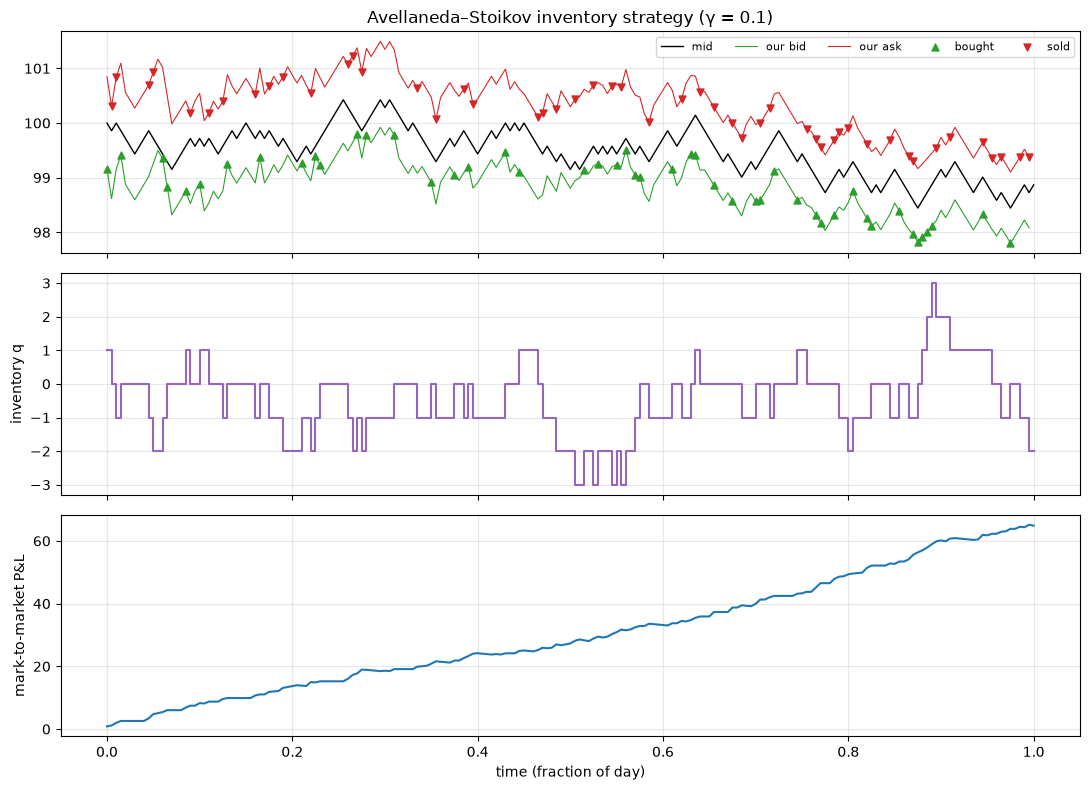

In [4]:
one = simulate(inventory_strategy(0.1), n_paths=1, seed=3, keep_paths=True, **P)
h = one["hist"]; tt = np.arange(len(h["s"])) * P["dt"]

fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ax[0].plot(tt, h["s"][:, 0], color="k", lw=1, label="mid")
ax[0].plot(tt, h["bid"][:, 0], color="tab:green", lw=0.8, label="our bid")
ax[0].plot(tt, h["ask"][:, 0], color="tab:red", lw=0.8, label="our ask")
fb = h["fb"][:, 0] > 0; fa = h["fa"][:, 0] > 0
ax[0].scatter(tt[fb], h["bid"][fb, 0], marker="^", color="tab:green", s=25, zorder=3, label="bought")
ax[0].scatter(tt[fa], h["ask"][fa, 0], marker="v", color="tab:red", s=25, zorder=3, label="sold")
ax[0].legend(ncol=5, fontsize=8); ax[0].set_title("Avellaneda–Stoikov inventory strategy (γ = 0.1)")
ax[1].step(tt, h["q"][:, 0], where="post", color="tab:purple"); ax[1].set_ylabel("inventory q")
ax[2].plot(tt, h["wealth"][:, 0], color="tab:blue"); ax[2].set_ylabel("mark-to-market P&L"); ax[2].set_xlabel("time (fraction of day)")
plt.tight_layout(); plt.show()

Notice how the quotes **skew** with inventory: after a few buys, both quotes drop, making the next fill more likely to be a sale. Near the end of the day (T − t → 0) the skew and the risk part of the spread shrink, because there's little time left for the price to move against you.

## 4 · Replicating the paper's results table

1000 simulated days per row. Paper values (Table 1–3 in the PDF) are shown alongside for comparison.

In [5]:
paper = {  # (γ, strategy): (profit, std profit, final q, std final q)
    (0.1, "inventory"): (62.94, 5.89, 0.08, 1.80),  (0.1, "symmetric"): (67.21, 13.43, -0.018, 8.66),
    (0.01, "inventory"): (66.78, 8.76, -0.02, 4.70), (0.01, "symmetric"): (67.36, 13.40, -0.31, 8.65),
    (0.5, "inventory"): (33.92, 4.72, -0.02, 1.88),  (0.5, "symmetric"): (66.20, 14.53, 0.25, 9.06),
}
rows = []
for gamma in (0.01, 0.1, 0.5):
    for name, strat in (("inventory", inventory_strategy), ("symmetric", symmetric_strategy)):
        r = simulate(strat(gamma), seed=42, **P)
        s_ = summary(r)
        p_ = paper[(gamma, name)]
        rows.append({"γ": gamma, "strategy": name,
                     "spread at t=0": as_quotes(0, 0, 0, gamma, P["sigma"], P["T"], P["k"])[1],
                     "mean P&L": s_["mean P&L"], "paper P&L": p_[0],
                     "std P&L": s_["std P&L"], "paper std": p_[1],
                     "std final q": s_["std final q"], "paper std q": p_[3]})
table = pd.DataFrame(rows).set_index(["γ", "strategy"])
table.round(2)

spread at t=0  mean P&L  paper P&L  std P&L  paper std  std final q  paper std q
γ    strategy                                                                                   
0.01 inventory           1.37     68.05      66.78     9.10       8.76         5.30         4.70
     symmetric           1.37     68.47      67.36    13.88      13.40         8.93         8.65
0.10 inventory           1.69     64.94      62.94     6.50       5.89         2.90         1.80
     symmetric           1.69     67.77      67.21    13.37      13.43         8.56         8.66
0.50 inventory           3.15     48.38      33.92     5.98       4.72         1.93         1.88
     symmetric           3.15     58.28      66.20    11.18      14.53         7.27         9.06

**Reading the table.**
* For γ = 0.01 and 0.1 the simulation lands close to the paper. For γ = 0.5 it doesn't: the paper's reported spreads (1.29, 1.33, 1.15) equal only the (2/γ)·ln(1 + γ/k) term, which suggests its simulation dropped the γσ²(T − t) part. Setting `PAPER_SPREAD = True` (below) reproduces the paper's symmetric results, but the paper doesn't give enough detail to match every number. Small differences across seeds are normal Monte Carlo noise.
* The symmetric strategy earns slightly more *on average*, but with roughly twice the volatility and wild inventory swings.
* The inventory strategy gives up a little mean P&L to cut risk sharply. Its mean/std ratio is much better.
* Higher γ means a tighter grip on inventory but a lower profit, because you skew so hard that you give away edge.

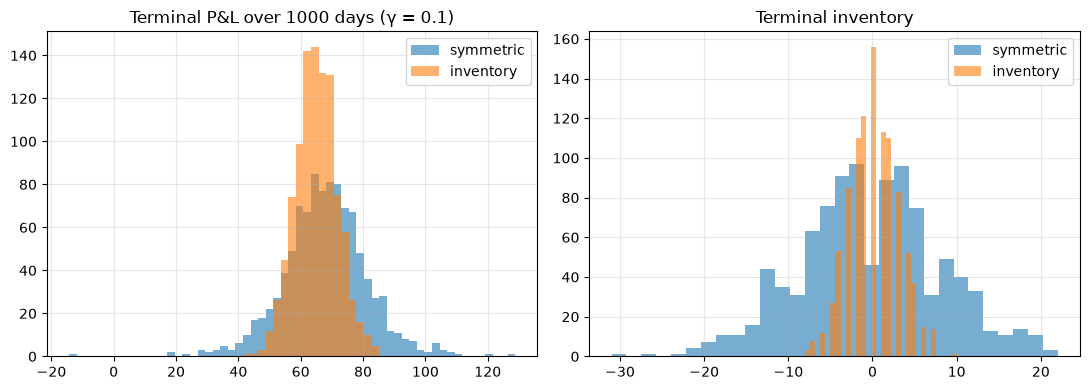

In [6]:
r_inv = simulate(inventory_strategy(0.1), seed=1, **P)
r_sym = simulate(symmetric_strategy(0.1), seed=1, **P)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(min(r_inv["pnl"].min(), r_sym["pnl"].min()), max(r_inv["pnl"].max(), r_sym["pnl"].max()), 60)
ax[0].hist(r_sym["pnl"], bins=bins, alpha=0.6, label="symmetric"); ax[0].hist(r_inv["pnl"], bins=bins, alpha=0.6, label="inventory")
ax[0].set_title("Terminal P&L over 1000 days (γ = 0.1)"); ax[0].legend()
ax[1].hist(r_sym["q"], bins=30, alpha=0.6, label="symmetric"); ax[1].hist(r_inv["q"], bins=30, alpha=0.6, label="inventory")
ax[1].set_title("Terminal inventory"); ax[1].legend()
plt.tight_layout(); plt.show()

### 4a · Where does the money come from?

Split P&L into **spread capture** (the distance from the mid at which each fill happened) and **inventory P&L** (everything else: the price moving while you hold a position).

In [7]:
dec = pd.DataFrame({
    "strategy": ["inventory", "symmetric"],
    "spread capture (mean)": [r_inv["capture"].mean(), r_sym["capture"].mean()],
    "inventory P&L (mean)": [r_inv["inv_pnl"].mean(), r_sym["inv_pnl"].mean()],
    "inventory P&L (std)": [r_inv["inv_pnl"].std(), r_sym["inv_pnl"].std()],
    "fills / day": [r_inv["fills"].mean(), r_sym["fills"].mean()],
}).set_index("strategy")
dec.round(2)

,spread capture (mean),inventory P&L (mean),inventory P&L (std),fills / day
strategy,,,,
inventory,64.91,0.09,2.87,97.02
symmetric,67.94,-0.09,11.77,91.68


The **edge is the spread**; inventory P&L is mostly **noise you'd like to remove**. The skew in the inventory strategy turns the inventory P&L slightly negative (you sell a bit cheap to get flat) but slashes its variance.

## 5 · Exact solution with inventory limits (Guéant–Lehalle–Fernandez-Tapia)

Avellaneda–Stoikov uses an approximation and allows unlimited inventory. Real desks have hard **position limits** (|q| ≤ Q). Guéant, Lehalle & Fernandez-Tapia show that, for this model, the exact optimal quotes come from a **matrix exponential**:

* M is a (2Q+1) × (2Q+1) tridiagonal matrix with M<sub>q,q</sub> = α·q², where α = kγσ²/2, and −η on both off-diagonals, where η = A·(1 + γ/k)<sup>−(1 + k/γ)</sup>.
* v(t) = exp(−M·(T − t)) · **1**
* δ<sup>b</sup>(t, q) = (1/k)·ln(v<sub>q</sub> / v<sub>q+1</sub>) + (1/γ)·ln(1 + γ/k)  (no bid at q = +Q)
* δ<sup>a</sup>(t, q) = (1/k)·ln(v<sub>q</sub> / v<sub>q−1</sub>) + (1/γ)·ln(1 + γ/k)  (no ask at q = −Q)

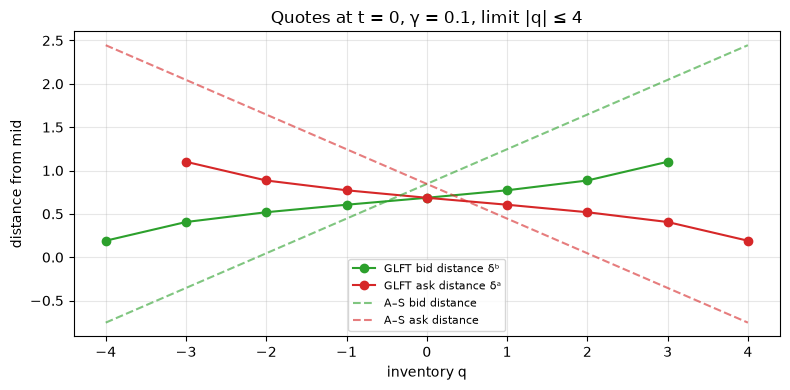

,mean P&L,std P&L,P&L / std,mean final q,std final q,fills / day
strategy,,,,,,
A–S inventory (no limit),65.11,6.50,10.02,0.04,2.87,96.90
"A–S inventory, hard cap 4",64.64,6.35,10.17,0.04,2.27,96.26
"GLFT exact, cap 4",66.76,6.39,10.45,0.00,1.89,101.03
"symmetric, hard cap 4",62.82,7.81,8.04,0.05,2.48,84.32


In [8]:
def glft_tables(gamma, Q, sigma=P["sigma"], T=P["T"], dt=P["dt"], k=P["k"], A=P["A"]):
    qs = np.arange(-Q, Q + 1)
    alpha = k * gamma * sigma**2 / 2
    eta = A * (1 + gamma / k) ** (-(1 + k / gamma))
    M = np.diag(alpha * qs.astype(float) ** 2) - eta * (np.eye(len(qs), k=1) + np.eye(len(qs), k=-1))
    n = int(round(T / dt))
    base = np.log(1 + gamma / k) / gamma
    db = np.full((n + 1, len(qs)), np.nan); da = np.full((n + 1, len(qs)), np.nan)
    for i in range(n + 1):
        v = expm(-M * (T - i * dt)) @ np.ones(len(qs))
        db[i, :-1] = np.log(v[:-1] / v[1:]) / k + base     # bid exists for q < Q
        da[i, 1:] = np.log(v[1:] / v[:-1]) / k + base      # ask exists for q > -Q
    return qs, db, da

def glft_strategy(gamma, Q):
    qs, db, da = glft_tables(gamma, Q)
    def f(s, q, t):
        i = int(round(t / P["dt"])); j = np.clip(q, -Q, Q).astype(int) + Q
        bd = np.nan_to_num(db[i, j], nan=1e6); ad = np.nan_to_num(da[i, j], nan=1e6)   # 'no quote' = very far away
        return s - bd, s + ad
    return f

Q = 4
qs, db, da = glft_tables(0.1, Q)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(qs, db[0], "o-", color="tab:green", label="GLFT bid distance δᵇ")
ax.plot(qs, da[0], "o-", color="tab:red", label="GLFT ask distance δᵃ")
r0, spr0 = as_quotes(0.0, qs.astype(float), 0.0, 0.1, P["sigma"], P["T"], P["k"])
ax.plot(qs, -(r0 - spr0 / 2), "--", color="tab:green", alpha=0.6, label="A–S bid distance")
ax.plot(qs, r0 + spr0 / 2, "--", color="tab:red", alpha=0.6, label="A–S ask distance")
ax.set_xlabel("inventory q"); ax.set_ylabel("distance from mid"); ax.set_title(f"Quotes at t = 0, γ = 0.1, limit |q| ≤ {Q}")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

rows = []
for name, strat, qm in (("A–S inventory (no limit)", inventory_strategy(0.1), None),
                        (f"A–S inventory, hard cap {Q}", inventory_strategy(0.1), Q),
                        (f"GLFT exact, cap {Q}", glft_strategy(0.1, Q), Q),
                        (f"symmetric, hard cap {Q}", symmetric_strategy(0.1), Q)):
    rows.append({"strategy": name, **summary(simulate(strat, seed=5, q_max=qm, **P))})
pd.DataFrame(rows).set_index("strategy").round(2)

## 6 · Adverse selection: the part that kills real market makers

In the textbook model, fills are uninformative: after you buy, the price is equally likely to go up or down. In real markets **the people who trade against you often know something**. Here, after each fill the mid jumps by `adverse` against you.

### 6a · Markouts

A **markout** measures how the mid moves after each fill, from your side: (mid<sub>t+h</sub> − fill price) for a buy, and the reverse for a sale. Desks watch this curve constantly. If it decays below zero, your spread isn't paying for the information you're giving away.

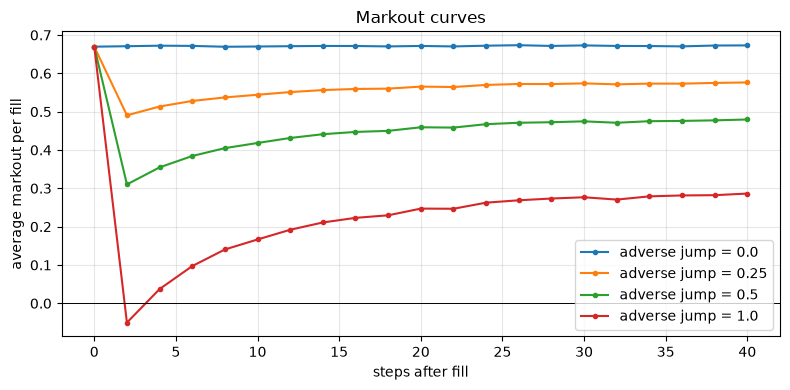

In [9]:
def markouts(hist, horizons):
    s, fb, fa = hist["s"], hist["fb"] > 0, hist["fa"] > 0
    bid, ask = hist["bid"], hist["ask"]
    out = []
    for hz in horizons:
        fut = s[hz:]                               # mid h steps later
        b = fb[:len(fut)]; a = fa[:len(fut)]
        mb = (fut - bid[:len(fut)])[b]; ma = (ask[:len(fut)] - fut)[a]
        out.append(np.concatenate([mb, ma]).mean())
    return np.array(out)

H = np.arange(0, 41, 2)
fig, ax = plt.subplots(figsize=(8, 4))
for adv in (0.0, 0.25, 0.5, 1.0):
    r = simulate(inventory_strategy(0.1), n_paths=400, seed=11, adverse=adv, keep_paths=True, **P)
    ax.plot(H, markouts(r["hist"], H), "o-", ms=3, label=f"adverse jump = {adv}")
ax.axhline(0, color="k", lw=0.7)
ax.set_xlabel("steps after fill"); ax.set_ylabel("average markout per fill"); ax.set_title("Markout curves")
ax.legend(); plt.tight_layout(); plt.show()

At horizon 0 the markout is just the half-spread you captured. With informed flow, it bleeds away as the price moves against you. The partial recovery afterwards comes from your *next* fill: thanks to the skew it's usually on the other side, and its own adverse jump pushes the price back your way. Real markouts rarely get that gift.

### 6b · Fighting back: widen the spread

Add an extra half-spread `widen` on both sides and see which width maximises risk-adjusted P&L for each level of adverse selection.

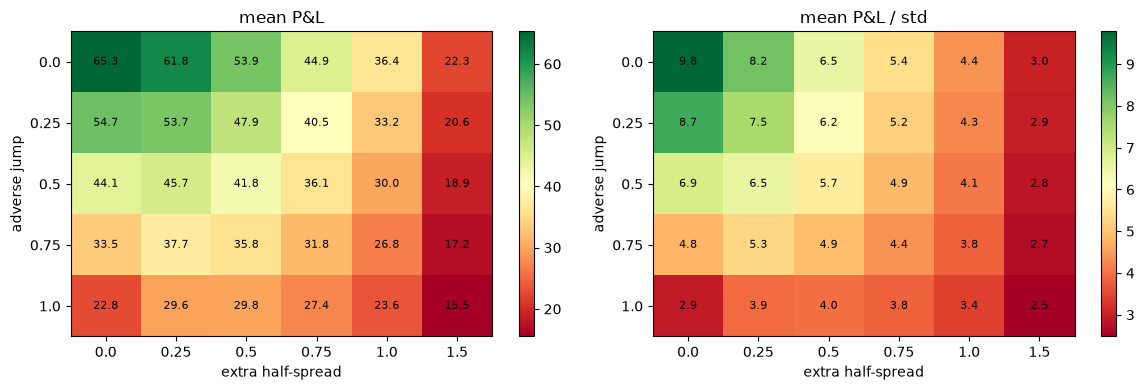

,best extra half-spread (by mean P&L)
0.00,0.00
0.25,0.00
0.50,0.25
0.75,0.25
1.00,0.50


In [10]:
def widened(base_fn, w):
    def f(s, q, t):
        b, a = base_fn(s, q, t)
        return b - w, a + w
    return f

advs = [0.0, 0.25, 0.5, 0.75, 1.0]
widens = [0.0, 0.25, 0.5, 0.75, 1.0, 1.5]
grid_mean = np.zeros((len(advs), len(widens))); grid_sr = np.zeros_like(grid_mean)
for i, adv in enumerate(advs):
    for j, w in enumerate(widens):
        r = simulate(widened(inventory_strategy(0.1), w), n_paths=500, seed=21, adverse=adv, **P)
        grid_mean[i, j] = r["pnl"].mean(); grid_sr[i, j] = r["pnl"].mean() / r["pnl"].std()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, g, title in ((ax[0], grid_mean, "mean P&L"), (ax[1], grid_sr, "mean P&L / std")):
    im = a_.imshow(g, cmap="RdYlGn", aspect="auto")
    a_.set_xticks(range(len(widens)), [str(w) for w in widens]); a_.set_yticks(range(len(advs)), [str(a) for a in advs])
    a_.set_xlabel("extra half-spread"); a_.set_ylabel("adverse jump"); a_.set_title(title); a_.grid(False)
    for (ii, jj), v in np.ndenumerate(g):
        a_.text(jj, ii, f"{v:.1f}", ha="center", va="center", fontsize=8)
    plt.colorbar(im, ax=a_)
plt.tight_layout(); plt.show()
best = pd.Series({adv: widens[int(np.argmax(grid_mean[i]))] for i, adv in enumerate(advs)}, name="best extra half-spread (by mean P&L)")
best.to_frame()

With harmless flow the best extra width is zero; as the flow gets more toxic, the best width grows. Widening costs volume, so beyond some level of toxicity quoting isn't worth it at all. That's why market makers pull quotes around news releases.

## 7 · Discussion

* **Skewing beats widening for inventory control.** Shifting both quotes towards the side that reduces inventory keeps the strategy competitive where it wants to be filled. Widening only cuts fills on both sides.
* **Reservation price.** A long position lowers the market maker's private fair value by q·γ·σ²·(T − t). The shade grows with inventory, risk aversion, volatility and time remaining.
* **What sets the spread.** Volatility (risk), the decay of fill probability with distance (k), and adverse selection, which the base model leaves out.
* **Calibrating A and k.** Count fills at different distances from the mid and fit log(fill rate) = log A − k·δ. On a one-tick futures book, queue position matters more than distance.
* **Model limitations.** Constant volatility, fills independent of future price moves, no queue priority, and a continuous price grid.

**Extensions**
* Use the micro-price as the reference price instead of the mid.
* Let σ follow a GARCH or regime-switching process.
* Learn γ with reinforcement learning: Falces Marín et al. (2022), *A reinforcement learning approach to improve the performance of the Avellaneda-Stoikov market-making algorithm*, PLOS ONE.